<a href="https://colab.research.google.com/github/fce-laboratoriotp/tp-labo/blob/main/An%C3%A1lisisSuicidios2020-2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TRABAJO PRÁCTICO GRUPAL - Laboratorio de Métodos Cuantitativos Aplicados a la Gestión

## **Tema del informe: Mortalidad por suicidios en Argentina durante el período 2020-2024.**

### **Integrantes del grupo**

Baldi, Miguelina - 920085 - baldimiguelina

Cabrera, Micaela - 921458 - Cabrera30micaela

Estrella, Kayra - 921472 - kayraa2003

Montenegro, Aldana - 921489 - AldanaMontenegro

Scavone, Florencia - 921420 - scavonemf



### **Objetivo general**

Analizar la evolución y distribución de los casos de suicidio en Argentina entre 2020 y 2024 según la edad y el sexo, para entender cómo varía la brecha entre varones y mujeres en las distintas etapas de la vida e identificar cuáles son los grupos más vulnerables sobre los que hay que priorizar la prevención.

### **Prompt utilizado**

## **Fuentes de Datos y Origen de la Información**

Para el desarrollo del presente trabajo práctico se utilizaron las bases de datos oficiales abiertas provistas por la *Dirección Nacional de Estadística Criminal (DNEC)* dependiente del *Ministerio de Seguridad de la Nación*, accesibles a través del portal oficial del Estado Argentino ([Argentina.gob.ar - Bases de Datos del SNIC](https://www.argentina.gob.ar/seguridad/estadisticascriminales/bases-de-datos)).

El análisis se estructuró a partir de dos insumos principales obtenidos de dicho repositorio:
1. *Base de estadísticas criminales a nivel provincial (snic-provincias.csv):* Empleada para auditar la macrovisión del fenómeno, la evolución temporal general del quinquenio 2020–2024 y la construcción de tasas relativas por jurisdicción.

2. *Base de microdatos unificados (SAT-SS-BU_2017-2024.csv):* Utilizada para desglosar el nivel de detalle individual por cada hecho registrado, permitiendo incorporar y explotar variables demográficas clave como el sexo, la identidad de género y la tramificación etaria de las víctimas.

# **3.1. Carga y exploración inicial**

### **Incorporación y exploración de la base provincial**

En esta etapa inicial examinamos la base de datos oficial a nivel provincial (`snic-provincias.csv`) para evaluar su estructura, identificar qué información aporta y verificar los registros del fenómeno en cada jurisdicción.

In [ ]:
import pandas as pd

# direccion donde estan guardados los archivos en el repositorio del grupo
URL_BASE = "https://raw.githubusercontent.com/fce-laboratoriotp/tp-labo/main/"

df_prov = pd.read_csv(URL_BASE + "snic-provincias.csv", sep=";", encoding="utf-8-sig", decimal=",", on_bad_lines="skip")

# miro el tamaño de la tabla
print("dimensiones de la tabla provincial:", df_prov.shape)

# reviso las primeras filas
display(df_prov.head(3))

# reviso las ultimas filas
display(df_prov.tail(3))

# reviso los tipos de datos de cada columna
print("\ntipos de datos:")
print(df_prov.dtypes)

# chequeo si hay valores nulos o celdas vacias
print("\nvalores nulos:")
print(df_prov.isnull().sum())

dimensiones de la tabla provincial: (26528, 14)


,provincia_id,provincia_nombre,anio,codigo_delito_snic_id,codigo_delito_snic_nombre,cantidad_hechos,cantidad_victimas,cantidad_victimas_masc,cantidad_victimas_fem,cantidad_victimas_sd,tasa_hechos,tasa_victimas,tasa_victimas_masc,tasa_victimas_fem
0,2,Ciudad Autónoma de Buenos Aires,2000,1,Homicidios dolosos,149,158.0,121.0,37.0,0.0,4.975001,5.275505,8.825701,2.278360
1,2,Ciudad Autónoma de Buenos Aires,2000,2,Homicidios dolosos en grado de tentativa,54,58.0,40.0,18.0,0.0,1.803021,1.936578,2.917587,1.108391
2,2,Ciudad Autónoma de Buenos Aires,2000,3,Muertes en accidentes viales,121,126.0,97.0,29.0,0.0,4.040102,4.207048,7.075148,1.785742


,provincia_id,provincia_nombre,anio,codigo_delito_snic_id,codigo_delito_snic_nombre,cantidad_hechos,cantidad_victimas,cantidad_victimas_masc,cantidad_victimas_fem,cantidad_victimas_sd,tasa_hechos,tasa_victimas,tasa_victimas_masc,tasa_victimas_fem
26525,94,"Tierra del Fuego, Antártida e Islas del Atlánt...",2025,30,Contravenciones,536,NaN,NaN,NaN,NaN,294.500640,NaN,NaN,NaN
26526,94,"Tierra del Fuego, Antártida e Islas del Atlánt...",2025,31,Suicidios (consumados),21,21.0,18.0,3.0,0.0,12.061964,12.061964,20.771548,3.430767
26527,94,"Tierra del Fuego, Antártida e Islas del Atlánt...",2025,32,Delitos contra el orden económico y financiero,0,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN



tipos de datos:
provincia_id                   int64
provincia_nombre              object
anio                           int64
codigo_delito_snic_id         object
codigo_delito_snic_nombre     object
cantidad_hechos                int64
cantidad_victimas            float64
cantidad_victimas_masc       float64
cantidad_victimas_fem        float64
cantidad_victimas_sd         float64
tasa_hechos                  float64
tasa_victimas                float64
tasa_victimas_masc           float64
tasa_victimas_fem            float64
dtype: object

valores nulos:
provincia_id                     0
provincia_nombre                 0
anio                             0
codigo_delito_snic_id            0
codigo_delito_snic_nombre        0
cantidad_hechos                  0
cantidad_victimas            16688
cantidad_victimas_masc       16688
cantidad_victimas_fem        16688
cantidad_victimas_sd         16688
tasa_hechos                      0
tasa_victimas                16688
tasa_victimas_m

### **Auditoría de valores nulos y estadísticas descriptivas**

Una vez cargada la base provincial, revisamos si los valores nulos afectan
al delito de interés. Filtramos las filas con `cantidad_victimas` nula y
comprobamos cuántas corresponden a “Suicidios”. También revisamos cobertura
temporal, cantidad de provincias, duplicados y estadísticas descriptivas
generales para dimensionar la base antes de filtrar.

In [ ]:
# filtramos los nulos para ver a que delitos corresponden
nulos_df = df_prov[df_prov["cantidad_victimas"].isnull()]

# contamos cuantos de esos nulos pertenecen a la categoria de suicidios
suicidios_nulos = nulos_df[nulos_df["codigo_delito_snic_nombre"].astype(str).str.contains("Suicidios", case=False, na=False)]

print(f"\ntotal de filas con nulos en todo el dataset: {len(nulos_df)}")
print(f"de esos nulos, cuantos corresponden a suicidios: {len(suicidios_nulos)}")

if len(suicidios_nulos) == 0:
    print("ninguno de los nulos afecta a los suicidios. estan en otros delitos.")
else:
    print("hay registros nulos en suicidios. vamos a ver en que anios ocurren:")
    display(suicidios_nulos[["anio", "codigo_delito_snic_nombre"]])

# cobertura temporal y geografica
print(f"anios abarcados: desde {df_prov['anio'].min()} hasta {df_prov['anio'].max()}")
print(f"cantidad de provincias: {df_prov['provincia_nombre'].nunique()}")

# chequeo de duplicados y estadisticas descriptivas
print(f"filas duplicadas: {df_prov.duplicated().sum()}")
display(df_prov.describe())


total de filas con nulos en todo el dataset: 16688
de esos nulos, cuantos corresponden a suicidios: 0
ninguno de los nulos afecta a los suicidios. estan en otros delitos.
anios abarcados: desde 2000 hasta 2025
cantidad de provincias: 24
filas duplicadas: 0


,provincia_id,anio,cantidad_hechos,cantidad_victimas,cantidad_victimas_masc,cantidad_victimas_fem,cantidad_victimas_sd,tasa_hechos,tasa_victimas,tasa_victimas_masc,tasa_victimas_fem
count,26528.000000,26528.000000,26528.000000,9840.000000,9840.000000,9840.000000,9840.000000,26528.000000,9840.000000,9840.000000,9840.000000
mean,48.007238,2014.889023,1643.681959,928.313516,382.185264,347.179472,198.949898,106.666718,56.967052,46.913984,44.901649
std,27.686072,7.635516,6440.062330,3797.370072,1790.946330,1696.074856,1517.548679,278.453480,136.954498,130.162802,126.211972
min,2.000000,2000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25.000000,2008.000000,5.000000,8.000000,0.000000,0.000000,0.000000,0.517003,1.200465,0.000000,0.000000
50%,48.000000,2017.000000,73.000000,66.000000,14.000000,11.000000,1.000000,8.350259,8.042955,3.379856,2.332606
75%,71.000000,2021.000000,603.000000,346.000000,92.000000,115.000000,25.000000,56.158677,28.601799,17.534870,22.433456
max,94.000000,2025.000000,143840.000000,75807.000000,30146.000000,45728.000000,61164.000000,6707.523400,1232.819800,1476.951500,1462.505000


### **Extracción y acotamiento del universo de estudio**

El siguiente paso metodológico consiste en extraer exclusivamente los registros asociados al delito de **Suicidios** de la base provincial y acotar el horizonte temporal al quinquenio **2020-2024**, en consonancia con los objetivos del trabajo.

In [ ]:
# seleccionamos los registros de suicidios para el periodo de estudio
df_prov_suicidios = df_prov[
    (df_prov["codigo_delito_snic_nombre"].astype(str).str.contains("Suicidios", case=False, na=False)) &
    (df_prov["anio"].between(2020, 2024))
].copy()

print(f"cantidad de observaciones seleccionadas para el analisis: {len(df_prov_suicidios)}")
display(df_prov_suicidios.head(3))

cantidad de observaciones seleccionadas para el analisis: 120


,provincia_id,provincia_nombre,anio,codigo_delito_snic_id,codigo_delito_snic_nombre,cantidad_hechos,cantidad_victimas,cantidad_victimas_masc,cantidad_victimas_fem,cantidad_victimas_sd,tasa_hechos,tasa_victimas,tasa_victimas_masc,tasa_victimas_fem
766,2,Ciudad Autónoma de Buenos Aires,2020,31,Suicidios (consumados),206,206.0,144.0,62.0,0.0,7.173604,7.173604,10.750039,4.046709
826,2,Ciudad Autónoma de Buenos Aires,2021,31,Suicidios (consumados),236,236.0,176.0,60.0,0.0,8.204244,8.204244,13.101389,3.913407
886,2,Ciudad Autónoma de Buenos Aires,2022,31,Suicidios (consumados),242,242.0,171.0,71.0,0.0,8.141679,8.141679,10.637305,5.202189


#### **Conclusiones parciales - Base Provincial:**
* **Cobertura y Estructura:** La base oficial del SNIC recopila información de las 24 jurisdicciones del país para el período analizado, lo que garantiza una cobertura geográfica y temporal completa a nivel macro.
* **Consistencia de Datos:** La auditoría de valores nulos confirmó que los registros vacíos corresponden a otras categorías de hechos ajenas al objeto de estudio, validando que el universo de suicidios se encuentra completo y sin inconsistencias estructurales. Asimismo, la ausencia de filas duplicadas asegura la confiabilidad de la base para el cálculo de tasas y agregados provinciales.

### **Incorporación y análisis de microdatos**

Para dar cumplimiento a los objetivos del trabajo práctico y acceder a variables demográficas clave (como tramos de edad, sexo e identidad de género), incorporamos la base de **microdatos** (`SAT-SS-BU_2017-2024.csv`). Procedemos a cargarla, inspeccionar su estructura y acotarla al mismo período de estudio.

In [ ]:
# cargamos la base de microdatos
df_micro = pd.read_csv(URL_BASE + "SAT-SS-BU_2017-2024.csv", sep=",", encoding="utf-8-sig", on_bad_lines="skip")

# inspeccionamos dimensiones y columnas
print("dimensiones de la base de microdatos:")
print(f"filas: {df_micro.shape[0]} | columnas: {df_micro.shape[1]}")

print("\ncolumnas disponibles en microdatos:")
print(df_micro.columns.tolist())

# vista preliminar de los registros
display(df_micro.head(3))

# reviso las ultimas filas de microdatos
display(df_micro.tail(3))

# filtramos los microdatos solo para 2020-2024
df_micro_2020_2024 = df_micro[df_micro["anio"].between(2020, 2024)].copy()

print("victimas en microdatos (2020-2024):", len(df_micro_2020_2024))
print("victimas en base provincial (2020-2024):", df_prov_suicidios["cantidad_victimas"].sum())

# chequeo de valores nulos en microdatos
print("\nvalores nulos en microdatos:")
print(df_micro_2020_2024.isnull().sum())

# chequeo de duplicados y estadisticas descriptivas en microdatos
print(f"filas duplicadas en microdatos: {df_micro_2020_2024.duplicated().sum()}")
display(df_micro_2020_2024.describe())

dimensiones de la base de microdatos:
filas: 30177 | columnas: 27

columnas disponibles en microdatos:
['id_hecho', 'tipo_persona_id', 'federal', 'provincia_id', 'provincia_nombre', 'departamento_id', 'departamento_nombre', 'localidad_id', 'localidad_nombre', 'anio', 'mes', 'fecha_hecho', 'hora_hecho', 'tipo_lugar', 'tipo_lugar_ampliado', 'tipo_lugar_otro', 'modalidad', 'modalidad_ampliado', 'modalidad_otro', 'motivo_origen_registro', 'motivo_origen_registro_otro', 'suicida_sexo', 'suicida_tr_edad', 'suicida_18_años_o_mas', 'suicida_clase', 'suicida_clase_otro', 'suicida_identidad_genero']


,id_hecho,tipo_persona_id,federal,provincia_id,provincia_nombre,departamento_id,departamento_nombre,localidad_id,localidad_nombre,anio,...,modalidad_ampliado,modalidad_otro,motivo_origen_registro,motivo_origen_registro_otro,suicida_sexo,suicida_tr_edad,suicida_18_años_o_mas,suicida_clase,suicida_clase_otro,suicida_identidad_genero
0,8529,Suicida idRegistro 20712,No,42,La Pampa,42002.0,Norte (General Pico),105030,General Pico,2017,...,Ahorcamiento,NaN,Intervención policial,NaN,Masculino,20-24,Si,Sin determinación,NaN,Sin determinar
1,8530,Suicida idRegistro 20713,No,42,La Pampa,42003.0,Sur (General Acha),70030,Guatraché,2017,...,Arma de fuego,NaN,Intervención policial,NaN,Masculino,55-59,Si,Sin determinación,NaN,Sin determinar
2,8569,Suicida idRegistro 20752,No,78,Santa Cruz,78021.0,Güer Aike,60,28 de Noviembre,2017,...,Ahorcamiento,NaN,Denuncia particular,NaN,Masculino,15-19,No,Sin determinación,NaN,Sin determinar


,id_hecho,tipo_persona_id,federal,provincia_id,provincia_nombre,departamento_id,departamento_nombre,localidad_id,localidad_nombre,anio,...,modalidad_ampliado,modalidad_otro,motivo_origen_registro,motivo_origen_registro_otro,suicida_sexo,suicida_tr_edad,suicida_18_años_o_mas,suicida_clase,suicida_clase_otro,suicida_identidad_genero
30174,52091,Suicida idRegistro 64674,No,14,Córdoba,14.0,Capital,10,Córdoba,2024,...,Sin determinar,NaN,Orden judicial,NaN,Masculino,25-29,Si,Civil,NaN,Varón
30175,52092,Suicida idRegistro 64675,No,62,Río Negro,21.0,Bariloche,60,San Carlos de Bariloche,2024,...,Ahorcamiento,NaN,Intervención policial,NaN,Masculino,30-34,Si,Civil,NaN,Varón
30176,52093,Suicida idRegistro 64676,No,14,Córdoba,161.0,Tercero Arriba,30,Corralito,2024,...,Ahorcamiento,NaN,Intervención policial,NaN,Masculino,90 y más,Si,Civil,NaN,Varón


victimas en microdatos (2020-2024): 19323
victimas en base provincial (2020-2024): 19323.0

valores nulos en microdatos:
id_hecho                           0
tipo_persona_id                    0
federal                            0
provincia_id                       0
provincia_nombre                   0
departamento_id                    2
departamento_nombre                0
localidad_id                       0
localidad_nombre                   0
anio                               0
mes                                0
fecha_hecho                        0
hora_hecho                         0
tipo_lugar                         0
tipo_lugar_ampliado                0
tipo_lugar_otro                18502
modalidad                          0
modalidad_ampliado                 0
modalidad_otro                 19139
motivo_origen_registro             0
motivo_origen_registro_otro    19314
suicida_sexo                       0
suicida_tr_edad                    0
suicida_18_años_o_mas       

,id_hecho,provincia_id,departamento_id,anio,mes,fecha_hecho
count,19323.00000,19323.000000,19321.000000,19323.000000,19323.000000,19323.000000
mean,36917.76691,35.864100,28062.522333,2022.130984,6.600010,44794.231331
std,8396.64198,31.001827,31049.941484,1.394339,3.592245,519.538025
min,20284.00000,2.000000,1.000000,2020.000000,1.000000,43831.000000
25%,29720.50000,6.000000,2010.000000,2021.000000,3.000000,44361.000000
50%,36714.00000,26.000000,10028.000000,2022.000000,7.000000,44829.000000
75%,44307.50000,66.000000,54014.000000,2023.000000,10.000000,45247.000000
max,52093.00000,94.000000,94014.000000,2024.000000,12.000000,45657.000000


#### **Conclusiones parciales - Base de Microdatos:**
* **Granularidad y Complementariedad:** A diferencia de la base provincial que maneja datos agregados, esta fuente de microdatos nos permite trabajar a nivel individual, analizando cada registro por separado.
* **Calidad y Validación:** Cuando revisamos los valores nulos, notamos que los faltantes están solo en variables de texto secundarias o cualitativas (como la descripción del lugar o detalles de la modalidad). Esto es clave porque no afecta a las variables demográficas principales que necesitamos para el análisis (suicida_sexo, suicida_tr_edad y provincia_id). Además, al comprobar que no hay filas duplicadas, pudimos hacer el cruce de datos con la base macro de forma limpia y confiable.

### **Comparación de esquemas entre fuentes**

Una vez filtradas ambas bases para el período **2020-2024**, comparamos sus columnas para identificar qué variables son comunes a ambas fuentes y cuáles son exclusivas de cada una.

In [ ]:
# comparacion de columnas entre la base provincial y la de microdatos
cols_prov = set(df_prov_suicidios.columns)
cols_micro = set(df_micro_2020_2024.columns)

comunes = cols_prov.intersection(cols_micro)
solo_en_prov = cols_prov - cols_micro
solo_en_micro = cols_micro - cols_prov

print(f"columnas comunes ({len(comunes)}):", sorted(list(comunes)))
print(f"columnas exclusivas de provincial ({len(solo_en_prov)}):", sorted(list(solo_en_prov)))
print(f"columnas exclusivas de microdatos ({len(solo_en_micro)}):", sorted(list(solo_en_micro)))

columnas comunes (3): ['anio', 'provincia_id', 'provincia_nombre']
columnas exclusivas de provincial (11): ['cantidad_hechos', 'cantidad_victimas', 'cantidad_victimas_fem', 'cantidad_victimas_masc', 'cantidad_victimas_sd', 'codigo_delito_snic_id', 'codigo_delito_snic_nombre', 'tasa_hechos', 'tasa_victimas', 'tasa_victimas_fem', 'tasa_victimas_masc']
columnas exclusivas de microdatos (24): ['departamento_id', 'departamento_nombre', 'fecha_hecho', 'federal', 'hora_hecho', 'id_hecho', 'localidad_id', 'localidad_nombre', 'mes', 'modalidad', 'modalidad_ampliado', 'modalidad_otro', 'motivo_origen_registro', 'motivo_origen_registro_otro', 'suicida_18_años_o_mas', 'suicida_clase', 'suicida_clase_otro', 'suicida_identidad_genero', 'suicida_sexo', 'suicida_tr_edad', 'tipo_lugar', 'tipo_lugar_ampliado', 'tipo_lugar_otro', 'tipo_persona_id']


### **Integración y validación de las bases de datos**

Para garantizar la precisión de nuestro trabajo, integramos los microdatos de suicidios (2020–2024) con la tabla provincial agregada que abarca las 24 jurisdicciones. Agrupamos temporalmente los registros individuales mediante .groupby() a nivel provincial solo para equiparar ambas fuentes y combinarlas con pd.merge() mediante las claves de año y provincia.

Optamos por utilizar merge() en lugar de concat() porque ambas fuentes tienen distintas unidades de observación: la base provincial maneja totales por jurisdicción y los microdatos corresponden a casos individuales. Si hubiéramos usado concat(), las filas se habrían apilado incorrectamente, mezclando niveles de información y duplicando el conteo de las víctimas.

Esta operación nos permitió confirmar la coincidencia exacta de los registros en los 120 cruces esperados (24 provincias por 5 años), validando la calidad de los datos antes de avanzar hacia el análisis cuantitativo.

In [ ]:
# Agrupamos los microdatos por provincia y año
resumen_micro = (
    df_micro_2020_2024.groupby(["anio", "provincia_id"])
    .agg(
        victimas_micro=("tipo_persona_id", "size")
    )
    .reset_index()
)

# Unificamos la información de ambas fuentes
unificado = df_prov_suicidios.merge(
    resumen_micro,
    on=["anio", "provincia_id"],
    how="outer",
    validate="one_to_one",
    indicator=True
)

# Comprobamos la correspondencia entre ambas bases
print("Correspondencia entre las bases:")
print(unificado["_merge"].value_counts())

# Calculamos las diferencias entre las cantidades
unificado["diferencia"] = (
    unificado["cantidad_victimas"] -
    unificado["victimas_micro"]
)

print("\nDiferencias encontradas:")
print(unificado["diferencia"].value_counts(dropna=False))

# Visualizamos la tabla resultante
display(unificado.head())

Correspondencia entre las bases:
_merge
both          120
left_only       0
right_only      0
Name: count, dtype: int64

Diferencias encontradas:
diferencia
0.0    120
Name: count, dtype: int64


,provincia_id,provincia_nombre,anio,codigo_delito_snic_id,codigo_delito_snic_nombre,cantidad_hechos,cantidad_victimas,cantidad_victimas_masc,cantidad_victimas_fem,cantidad_victimas_sd,tasa_hechos,tasa_victimas,tasa_victimas_masc,tasa_victimas_fem,victimas_micro,_merge,diferencia
0,2,Ciudad Autónoma de Buenos Aires,2020,31,Suicidios (consumados),206,206.0,144.0,62.0,0.0,7.173604,7.173604,10.750039,4.046709,206,both,0.0
1,6,Buenos Aires,2020,31,Suicidios (consumados),858,858.0,688.0,166.0,4.0,5.320633,5.320633,8.732162,2.012858,858,both,0.0
2,10,Catamarca,2020,31,Suicidios (consumados),48,48.0,39.0,9.0,0.0,12.595483,12.595483,20.498912,4.716116,48,both,0.0
3,14,Córdoba,2020,31,Suicidios (consumados),197,197.0,158.0,35.0,4.0,5.685956,5.685956,9.363690,1.969270,197,both,0.0
4,18,Corrientes,2020,31,Suicidios (consumados),36,36.0,32.0,4.0,0.0,3.530852,3.530852,6.388386,0.771196,36,both,0.0


### Persistencia de archivos procesados

Guardamos dos archivos intermedios en el entorno de trabajo:
- `suicidios_microdatos_2020_2024.csv`: microdatos filtrados al quinquenio.
- `validacion_provincias_2020_2024.csv`: tabla de validación cruzada entre base provincial y microdatos.

Esto permite reutilizarlos en los análisis posteriores sin recalcular la integración desde cero y asegura la reproducibilidad del proceso.

In [ ]:
# Guardamos los microdatos para los análisis posteriores
df_micro_2020_2024.to_csv(
    "suicidios_microdatos_2020_2024.csv",
    index=False
)

# Guardamos la tabla de validación provincial
unificado.to_csv(
    "validacion_provincias_2020_2024.csv",
    index=False
)

print("Archivos guardados correctamente.")


Archivos guardados correctamente.


### Construcción del DataFrame máster

Unimos los microdatos individuales con las métricas provinciales agregadas
usando `anio` y `provincia_id` como claves. El resultado (`df_master`)
combina variables demográficas a nivel individuo (`suicida_sexo`,
`suicida_tr_edad`, etc.) con tasas y totales provinciales.
Se usa `how="left"` para conservar todos los microdatos.

In [ ]:
# CREACIÓN DEL DATAFRAME MÁSTER (UNIFICACIÓN TOTAL DE COLUMNAS)

# Unimos los microdatos individuales (que ya tienen el orden de edad) con las métricas provinciales
df_master = pd.merge(
    df_micro_2020_2024,
    df_prov_suicidios,
    on=["anio", "provincia_id"],
    how="left",
    suffixes=("_micro", "_prov")
)

# Control de dimensiones y guardado del master completo para los gráficos
print(f"Dimensiones de df_master -> Filas: {df_master.shape[0]} | Columnas: {df_master.shape[1]}")
df_master.to_csv("suicidios_master_2020_2024.csv", index=False)
print("Archivo 'suicidios_master_2020_2024.csv' guardado correctamente.")


# Vista previa para confirmar que tenemos 'suicida_tr_edad' y las columnas provinciales juntas
display(df_master.head(2))

# Mostramos el listado completo de columnas unidas en el df_master
print(f"Dimensiones de df_master -> Filas: {df_master.shape[0]} | Columnas: {df_master.shape[1]}")
print("\nListado completo de columnas en el df_master:")
print(df_master.columns.tolist())

# Mostramos únicamente la columna de tramos de edad
print("\nVista exclusiva de la columna 'suicida_tr_edad':")
display(df_master[["suicida_tr_edad"]])

Dimensiones de df_master -> Filas: 19323 | Columnas: 39
Archivo 'suicidios_master_2020_2024.csv' guardado correctamente.


,id_hecho,tipo_persona_id,federal,provincia_id,provincia_nombre_micro,departamento_id,departamento_nombre,localidad_id,localidad_nombre,anio,...,codigo_delito_snic_nombre,cantidad_hechos,cantidad_victimas,cantidad_victimas_masc,cantidad_victimas_fem,cantidad_victimas_sd,tasa_hechos,tasa_victimas,tasa_victimas_masc,tasa_victimas_fem
0,20284,Suicida idRegistro 32567,No,18,Corrientes,18021.0,Capital,20,Corrientes,2020,...,Suicidios (consumados),36,36.0,32.0,4.0,0.0,3.530852,3.530852,6.388386,0.771196
1,20285,Suicida idRegistro 32568,No,18,Corrientes,18119.0,Paso de los Libres,30,Paso de los Libres,2020,...,Suicidios (consumados),36,36.0,32.0,4.0,0.0,3.530852,3.530852,6.388386,0.771196


Dimensiones de df_master -> Filas: 19323 | Columnas: 39

Listado completo de columnas en el df_master:
['id_hecho', 'tipo_persona_id', 'federal', 'provincia_id', 'provincia_nombre_micro', 'departamento_id', 'departamento_nombre', 'localidad_id', 'localidad_nombre', 'anio', 'mes', 'fecha_hecho', 'hora_hecho', 'tipo_lugar', 'tipo_lugar_ampliado', 'tipo_lugar_otro', 'modalidad', 'modalidad_ampliado', 'modalidad_otro', 'motivo_origen_registro', 'motivo_origen_registro_otro', 'suicida_sexo', 'suicida_tr_edad', 'suicida_18_años_o_mas', 'suicida_clase', 'suicida_clase_otro', 'suicida_identidad_genero', 'provincia_nombre_prov', 'codigo_delito_snic_id', 'codigo_delito_snic_nombre', 'cantidad_hechos', 'cantidad_victimas', 'cantidad_victimas_masc', 'cantidad_victimas_fem', 'cantidad_victimas_sd', 'tasa_hechos', 'tasa_victimas', 'tasa_victimas_masc', 'tasa_victimas_fem']

Vista exclusiva de la columna 'suicida_tr_edad':


,suicida_tr_edad
0,30-34
1,55-59
2,35-39
3,50-54
4,50-54
...,...
19318,20-24
19319,35-39
19320,25-29
19321,30-34


## **Auditoría de integridad y consistencia del dataset**

Una vez integradas las bases SNIC Provincias y SNIC Microdatos, realizamos una serie de controles automáticos para verificar la integridad de la información utilizada en el análisis.

En primer lugar, comprobamos que la creación del DataFrame máster no haya provocado pérdidas ni multiplicaciones de registros individuales. Posteriormente, verificamos que todas las combinaciones de provincia y año tengan correspondencia entre ambas fuentes y que las cantidades de víctimas coincidan.

Finalmente, contrastamos los totales nacionales obtenidos a partir de ambas bases y examinamos la presencia de valores desconocidos en las variables demográficas.

Estas verificaciones permiten identificar posibles inconsistencias y evaluar la confiabilidad de los datos antes de realizar el análisis estadístico.

In [ ]:
# AUDITORÍA DE INTEGRIDAD Y CONSISTENCIA

# 1. Verificamos las dimensiones
print("1. CONTROL DE DIMENSIONES")

print("Microdatos:", len(df_micro_2020_2024))
print("Base máster:", len(df_master))
print("Tabla de validación:", len(unificado))

assert len(df_master) == len(df_micro_2020_2024), \
    "ERROR: El merge modificó la cantidad de registros"

print("OK: Se conservaron todos los microdatos.")


# 2. Validamos la correspondencia entre fuentes
print("\n2. CORRESPONDENCIA PROVINCIAL")

print(unificado["_merge"].value_counts())

assert (unificado["_merge"] == "both").all(), \
    "ERROR: Existen registros sin correspondencia"

assert unificado["diferencia"].notna().all(), \
    "ERROR: Hay diferencias sin calcular"

assert (unificado["diferencia"] == 0).all(), \
    "ERROR: Las cantidades no coinciden"

print("OK: Las cantidades coinciden por año y provincia.")


# 3. Comprobamos los totales nacionales
print("\n3. VALIDACIÓN DE TOTALES")

total_micro = len(df_micro_2020_2024)

total_prov = df_prov_suicidios[
    "cantidad_victimas"
].sum()

print("Total microdatos:", total_micro)
print("Total provincial:", total_prov)

assert total_micro == total_prov, \
    "ERROR: Los totales nacionales no coinciden"

print("OK: Ambos totales coinciden.")


# 4. Revisamos información demográfica desconocida
print("\n4. CALIDAD DE VARIABLES DEMOGRÁFICAS")

for columna in ["suicida_tr_edad", "suicida_sexo"]:

    nulos = df_master[columna].isna().sum()

    desconocidos = (
        df_master[columna]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("sin determinar")
        .sum()
    )

    print(f"\nVariable: {columna}")
    print("Valores nulos:", nulos)
    print("Sin determinar:", desconocidos)


print("\nAUDITORÍA FINALIZADA")


1. CONTROL DE DIMENSIONES
Microdatos: 19323
Base máster: 19323
Tabla de validación: 120
OK: Se conservaron todos los microdatos.

2. CORRESPONDENCIA PROVINCIAL
_merge
both          120
left_only       0
right_only      0
Name: count, dtype: int64
OK: Las cantidades coinciden por año y provincia.

3. VALIDACIÓN DE TOTALES
Total microdatos: 19323
Total provincial: 19323.0
OK: Ambos totales coinciden.

4. CALIDAD DE VARIABLES DEMOGRÁFICAS

Variable: suicida_tr_edad
Valores nulos: 0
Sin determinar: 844

Variable: suicida_sexo
Valores nulos: 0
Sin determinar: 132

AUDITORÍA FINALIZADA


### **Evaluación de calidad de los datos demográficos**

En esta sección analizamos qué tan completos están los datos sobre la edad y el sexo de las personas registradas en el dataset.

Para eso, identificamos tanto los valores nulos como las categorías clasificadas como «Sin determinar», marcando la diferencia entre los casos donde la información directamente falta y aquellos en los que se registró de forma explícita como desconocida.

Después, calculamos la cantidad y el porcentaje de registros con datos desconocidos para cada año del período 2020–2024. Esto nos sirve para ver si la calidad de la carga de datos fue cambiando con el tiempo y tener en cuenta estas limitaciones antes de hacer el análisis estadístico.

Vale aclarar que en esta etapa no eliminamos ni modificamos ningún registro, ya que el objetivo es hacer una evaluación meramente descriptiva de la calidad de la base.

***Prompt utilizado:***

"A partir del DataFrame df_master, necesito evaluar la calidad de la información demográfica correspondiente a las variables suicida_tr_edad y suicida_sexo durante el período 2020–2024.

Identificá tanto los valores nulos como los registros clasificados bajo la categoría «Sin determinar», considerando ambos casos como información desconocida.

Para cada variable, agrupá los registros por año mediante groupby() y calculá la cantidad total de observaciones, el número de registros desconocidos y el porcentaje que representan respecto del total anual.

Reuní los resultados en un único DataFrame llamado calidad_demografica, utilizando pd.concat(), y organizá las columnas para facilitar su interpretación.

Finalmente, mostrá la tabla con los porcentajes redondeados a dos decimales, de manera que sea posible comparar la completitud de la información entre años y variables. No elimines ni modifiques registros de df_master, ya que este procedimiento tiene una finalidad exclusivamente exploratoria."

***Inteligencia artificial utilizada:*** chat GPT

In [ ]:

# CALIDAD DE LOS DATOS DEMOGRÁFICOS POR AÑO

columnas = {
    "suicida_tr_edad": "Edad",
    "suicida_sexo": "Sexo"
}

resultados = []

for columna, nombre in columnas.items():

    # Identificamos datos ausentes o sin determinar
    desconocido = (
        df_master[columna].isna()
        | df_master[columna].astype(str)
          .str.strip().str.lower()
          .eq("sin determinar")
    )

    # Calculamos cantidades y porcentajes por año
    tabla = (
        df_master.assign(dato_desconocido=desconocido)
        .groupby("anio", as_index=False)
        .agg(
            total_registros=("dato_desconocido", "size"),
            desconocidos=("dato_desconocido", "sum")
        )
    )

    tabla["variable"] = nombre

    tabla["porcentaje_desconocido"] = (
        tabla["desconocidos"]
        / tabla["total_registros"] * 100
    )

    resultados.append(tabla)

# Reunimos los resultados
calidad_demografica = pd.concat(
    resultados, ignore_index=True
)

# Ordenamos las columnas
calidad_demografica = calidad_demografica[
    ["anio", "variable", "total_registros",
     "desconocidos", "porcentaje_desconocido"]
]

display(calidad_demografica.round(2))


,anio,variable,total_registros,desconocidos,porcentaje_desconocido
0,2020,Edad,3262,126,3.86
1,2021,Edad,3648,139,3.81
2,2022,Edad,3959,193,4.87
3,2023,Edad,4205,225,5.35
4,2024,Edad,4249,161,3.79
5,2020,Sexo,3262,8,0.25
6,2021,Sexo,3648,12,0.33
7,2022,Sexo,3959,37,0.93
8,2023,Sexo,4205,58,1.38
9,2024,Sexo,4249,17,0.40


**Interpretación de los resultados de la calidad de los datos demográficos:**

A partir de los cálculos que hicimos, notamos que durante todo el período 2020–2024 la variable edad tiene una proporción más alta de datos desconocidos que la variable sexo.

Para la edad, los valores sin determinar se mueven entre el 3,79% y el 5,35%. El punto más alto se dio en 2023, donde llegamos a tener 225 registros sin información sobre la edad. Por suerte, en 2024 esta cifra bajó al 3,79%, lo que marca una mejora respecto al año anterior.

En cambio, la variable sexo muestra porcentajes bastante más bajos, que van del 0,25% al 1,38%. Al igual que con la edad, el pico con más registros sin determinar también fue en 2023 (con 58 casos) y después volvió a bajar en 2024, alcanzando un 0,40%.

En resumen, ambas variables tuvieron su peor momento de carga de datos en 2023 y mostraron una recuperación en 2024. Esto nos deja ver que no hubo una mejora constante año a año durante el quinquenio, sino más bien ciertas fluctuaciones en la completitud de las planillas.

Tener en cuenta estos valores es fundamental para los pasos siguientes, porque esos casos de edad o sexo sin determinar pueden distorsionar los gráficos y las distribuciones por grupos demográficos. Por eso, preferimos no borrar estos datos, sino dejarlos explícitamente etiquetados como «Sin determinar» y considerarlos como una limitación propia de la base al momento de sacar conclusiones.

## **3.2. Pregunta de Investigación**

### **a) ¿Cuál es la pregunta?**
¿Cómo evolucionó la mortalidad por suicidio en Argentina entre 2020 y 2024, qué franjas etarias concentran la mayor vulnerabilidad y cómo se comporta la brecha entre varones y mujeres a lo largo de este período?
### **b) ¿Por qué vale la pena responderla?**
Vale la pena responder esta pregunta porque el suicidio representa una problemática de salud pública crítica y prevenible, que afectó a más de 19.000 personas en Argentina entre 2020 y 2024. Analizar este período permite evaluar la evolución del fenómeno durante la pandemia y pospandemia de COVID-19, identificar los grupos de edad de mayor vulnerabilidad y medir la disparidad entre varones y mujeres, aportando evidencia empírica para orientar recursos y diseñar políticas de prevención más efectivas.
### **c) ¿Qué respuesta encontraron?**
Encontramos que la mortalidad por suicidio mostró un crecimiento constante durante los años 2020–2024, pasando de 3.262 a 4.249 fallecimientos anuales. Los datos revelan que el riesgo se concentra fuertemente en los grupos de edad jóvenes (de 15 a 34 años, con su punto máximo entre los 20 y 29) y confirman una diferencia de género amplia y sostenida, registrándose aproximadamente cuatro suicidios de varones por cada mujer a lo largo de todo el período.

## **3.3. Transformaciones y resumen estadístico**

Para analizar el volumen de más de 19.000 registros del dataset máster, fue necesario resumir la información mediante la función .groupby() de pandas. Esto nos permitió condensar los microdatos individuales en métricas estadísticas agregadas según tres ejes estratégicos:

1. **Evolución anual** (.groupby("anio")): Consolida el total de víctimas por cada año para evaluar si el fenómeno se mantuvo estable o creció entre 2020 y 2024.
2. **Distribución por edad** (.groupby("suicida_tr_edad")): Sumariza las frecuencias absolutas por franjas de edad ordenadas para detectar en qué etapas de la vida se concentra el mayor volumen de casos.
3. **Brecha por sexo y año** (.groupby(["anio", "suicida_sexo"])): Agrupa simultáneamente por año y sexo, lo que nos permite calcular la razón o ratio de mortalidad entre varones y mujeres a lo largo de todo el período.

Adicionalmente, se justifican dos transformaciones clave en los datos: el filtrado explícito del quinquenio 2020–2024 y la conversión del tramo de edad a tipo categórico ordenado para garantizar que las tablas y gráficos mantengan la secuencia biológica correcta.

In [ ]:
# BLOQUE 1: CÁLCULO DE TABLAS Y NÚMEROS AGRUPADOS
import pandas as pd
#ASEGURAMOS EL ORDEN BIOLÓGICO DE TRAMOS DE EDAD (DE MENOR A MAYOR)

orden_edad = [
    '5-9', '10-14', '15-19', '20-24', '25-29', '30-34', '35-39',
    '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74',
    '75-79', '80-84', '85-89', '90 y más', 'Sin determinar'
]

df_master["suicida_tr_edad"] = pd.Categorical(
    df_master["suicida_tr_edad"], categories=orden_edad, ordered=True
)

# 1. TOTAL DE VÍCTIMAS POR AÑO (Evolución temporal)
# Agrupamos por 'anio' y contamos la cantidad de personas (filas) por año

resumen_anual = df_master.groupby("anio").size().reset_index(name="total_victimas")

#Creamos la fila del total sumando la columna "total_vistimas"
fila_total= pd.DataFrame([{"anio": "total",
                           "total_victimas":resumen_anual["total_victimas"].sum()
                           }])
#Unimos la tabla con la fila de total al final
resumen_anual = pd.concat([resumen_anual, fila_total], ignore_index=True)

print("1. EVOLUCIÓN ANUAL (2020-2024)")
display(resumen_anual)

# 2. TOTAL DE VÍCTIMAS POR EDAD (Franjas etarias)

resumen_edad = df_master.groupby("suicida_tr_edad", observed=False).size().reset_index(name="total_victimas")

print("\n2. CASOS POR FRANJA DE EDAD")
display(resumen_edad)

# 3. COMPARACIÓN DE VARONES VS MUJERES POR AÑO (Brecha de género)
# Agrupamos por año y por sexo, y ponemos los sexos en columnas separadas

resumen_sexo = df_master.groupby(["anio", "suicida_sexo"], observed=False).size().unstack(fill_value=0)

# Calculamos la relación: dividimos Varones / Mujeres. Permite cuantificar numéricamente y de manera directa la brecha de género por año.
resumen_sexo["Relacion_Varones_por_Mujer"] = (resumen_sexo["Masculino"] / resumen_sexo["Femenino"]).round(2)

print("\n3. BRECHA DE GÉNERO POR AÑO")
display(resumen_sexo)

1. EVOLUCIÓN ANUAL (2020-2024)


,anio,total_victimas
0,2020,3262
1,2021,3648
2,2022,3959
3,2023,4205
4,2024,4249
5,total,19323



2. CASOS POR FRANJA DE EDAD


,suicida_tr_edad,total_victimas
0,5-9,9
1,10-14,300
2,15-19,1830
3,20-24,2557
4,25-29,2472
5,30-34,2038
6,35-39,1572
7,40-44,1387
8,45-49,1173
9,50-54,940



3. BRECHA DE GÉNERO POR AÑO


suicida_sexo,Femenino,Masculino,Sin determinar,Relacion_Varones_por_Mujer
anio,,,,
2020,643,2611,8,4.06
2021,754,2882,12,3.82
2022,859,3063,37,3.57
2023,868,3279,58,3.78
2024,807,3425,17,4.24


### **Acondicionamiento y Preparación de Variables para el Análisis Agrupado**

Para que el procesamiento de datos y la posterior visualización resulten precisos, aplicamos una serie de adecuaciones técnicas sobre las variables de edad y sexo antes de generar las tablas y gráficos:

1.   Gestión de la variable etaria (df_master_edad):


*   Secuencia biológica: Convertimos la columna de edad en una variable categórica ordenada (de 5–9 a 90 y más años) para evitar que Python la ordene de manera alfabética.
*   Separación de casos "Sin determinar": Identificamos 844 registros (4,3%) sin dato de edad. Para no distorsionar la curva de vulnerabilidad en los gráficos ni dejar espacios vacíos en los ejes, creamos la tabla df_master_edad con los 18.479 casos confirmados. La base general df_master se mantuvo intacta con los 19.323 registros para no alterar el total nacional.


2.   Acondicionamiento para el análisis de género:


*   Prevencion de errores de calculo: Al cruzar año y sexo para calcular la brecha de mortalidad(division de varones sobre mujeres), cualquier combinacion sin genero generaria un valor nulo (NaN), lo que interrumpe la operaqcion matematica. La asignacion implicita de ceros aisla el efecto de las celdas vacias, garantizando que el calculo de la razon y la graficacion de la tendencia se ejecuten sin fallas de codigo.





In [ ]:
# CREACIÓN Y VERIFICACIÓN DE LA BASE FILTRADA POR EDAD (df_master_edad)
# 1. Filtramos las filas para excluir 'Sin determinar'
df_master_edad = df_master[df_master["suicida_tr_edad"] != "Sin determinar"].copy()

# 2. Eliminamos 'Sin determinar' de las categorías internas de la columna
if hasattr(df_master_edad["suicida_tr_edad"], "cat"):
    df_master_edad["suicida_tr_edad"] = df_master_edad["suicida_tr_edad"].cat.remove_unused_categories()

# 3. Verificamos los resultados
conteo_edad = (df_master_edad.groupby("suicida_tr_edad", observed=False)
              .size()
              .reset_index(name="total_victimas")
              )

print("1. CONTEO DE CASOS POR FRANJA DE EDAD (CASOS CONFIRMADOS)")
display(conteo_edad)

print("\nCONTROL DE FILAS TOTALES")
print(f"Filas en base original (df_master):  {len(df_master):,}")
print(f"Filas en base filtrada (df_master_edad):  {len(df_master_edad):,}")

#4. Resta para obtener los casos excluidos sin error de sintaxis
print(f"Casos excluidos (Sin determinar):    {len(df_master) - len(df_master_edad):,} ")

#VERIFICACION DE LA VARIABLE DE GENERO
#1. Obtenemos el conteo de casos por genero como DataFrame

conteo_sexo = (
    df_master["suicida_sexo"]
    .value_counts(dropna=False)
    .reset_index(name="total_victimas")
)

print("2. DISTRIBUCION TOTAL POR GENERO (2020-2024)")
display(conteo_sexo)

#2. Calculamos los porcentajes relativos
porcentajes_sexo = (
    df_master["suicida_sexo"]
    .value_counts(normalize=True, dropna=False)*100
).round(2).reset_index(name="porcentaje_%")

print("\nPORCENTAJE POR GÉNERO")
display(porcentajes_sexo)

1. CONTEO DE CASOS POR FRANJA DE EDAD (CASOS CONFIRMADOS)


,suicida_tr_edad,total_victimas
0,5-9,9
1,10-14,300
2,15-19,1830
3,20-24,2557
4,25-29,2472
5,30-34,2038
6,35-39,1572
7,40-44,1387
8,45-49,1173
9,50-54,940



CONTROL DE FILAS TOTALES
Filas en base original (df_master):  19,323
Filas en base filtrada (df_master_edad):  18,479
Casos excluidos (Sin determinar):    844 
2. DISTRIBUCION TOTAL POR GENERO (2020-2024)


,suicida_sexo,total_victimas
0,Masculino,15260
1,Femenino,3931
2,Sin determinar,132



PORCENTAJE POR GÉNERO


,suicida_sexo,porcentaje_%
0,Masculino,78.97
1,Femenino,20.34
2,Sin determinar,0.68


### **Análisis de variación interanual de suicidios (2020–2024)**

Con el objetivo de complementar el análisis de evolución temporal, calculamos la variación absoluta y porcentual de la cantidad de suicidios registrados entre años consecutivos.

La variación absoluta representa la diferencia en la cantidad de casos respecto del año anterior, mientras que la variación porcentual expresa esa diferencia en relación con la cantidad registrada durante el año previo.

Este procedimiento permite identificar los períodos con mayores aumentos o disminuciones y evaluar si la evolución observada presenta un comportamiento uniforme.

Los cálculos se realizan sobre los microdatos integrados en df_master, sin modificar sus registros originales. Se analizan cantidades absolutas de casos y no tasas poblacionales.

In [ ]:
# Calculamos los casos registrados por año
evolucion_anual = (
    df_master.groupby("anio")
    .size()
    .reset_index(name="cantidad")
    .sort_values("anio")
)

# Calculamos la variación absoluta
evolucion_anual["variacion_absoluta"] = (
    evolucion_anual["cantidad"].diff()
)

# Calculamos la variación porcentual
evolucion_anual["variacion_porcentual"] = (
    evolucion_anual["cantidad"].pct_change() * 100
)

# Mostramos los resultados
display(evolucion_anual.round(2))

# Verificamos que no perdimos observaciones
assert evolucion_anual["cantidad"].sum() == len(df_master), (
    "ERROR: No coinciden los totales"
)

print("Control de totales correcto.")


,anio,cantidad,variacion_absoluta,variacion_porcentual
0,2020,3262,NaN,NaN
1,2021,3648,386.0,11.83
2,2022,3959,311.0,8.53
3,2023,4205,246.0,6.21
4,2024,4249,44.0,1.05


Control de totales correcto.


### **Participación provincial en el total nacional de suicidios (2020–2024)**

Para complementar las comparaciones territoriales, calculamos el porcentaje que representa cada provincia sobre el total de suicidios registrados en el país durante el período 2020–2024.

Para esto, agrupamos los registros por provincia, sumamos la cantidad acumulada de casos en los cinco años y sacamos la proporción de cada jurisdicción sobre el total nacional.

Este análisis nos sirve para ver cómo se distribuyen geográficamente los casos en números absolutos. Es importante aclarar que estos porcentajes no representan tasas de mortalidad ni miden el riesgo individual en cada provincia, ya que no están ajustados por la cantidad de habitantes.

In [ ]:
import pandas as pd
import os

# Verificamos si 'df_master' existe en el espacio de nombres; si no, intentamos recuperarlo o reconstruirlo
if 'df_master' not in locals() and 'df_master' not in globals():
    archivo_csv = "suicidios_master_2020_2024.csv"
    if os.path.exists(archivo_csv):
        print(f"'df_master' no estaba en memoria. Cargando desde '{archivo_csv}'...")
        df_master = pd.read_csv(archivo_csv)
    else:
        print("'df_master' no está en memoria y el archivo local no existe. Reconstruyendo el dataset máster automáticamente...")
        URL_BASE = "https://raw.githubusercontent.com/fce-laboratoriotp/tp-labo/main/"

        # Cargamos y filtramos base provincial
        df_prov = pd.read_csv(URL_BASE + "snic-provincias.csv", sep=";", encoding="utf-8-sig", decimal=",", on_bad_lines="skip")
        df_prov_suicidios = df_prov[
            (df_prov["codigo_delito_snic_nombre"].astype(str).str.contains("Suicidios", case=False, na=False)) &
            (df_prov["anio"].between(2020, 2024))
        ].copy()

        # Cargamos y filtramos microdatos
        df_micro = pd.read_csv(URL_BASE + "SAT-SS-BU_2017-2024.csv", sep=",", encoding="utf-8-sig", on_bad_lines="skip")
        df_micro_2020_2024 = df_micro[df_micro["anio"].between(2020, 2024)].copy()

        # Unimos ambas fuentes para reconstruir df_master
        df_master = pd.merge(
            df_micro_2020_2024,
            df_prov_suicidios,
            on=["anio", "provincia_id"],
            how="left",
            suffixes=("_micro", "_prov")
        )
        df_master.to_csv(archivo_csv, index=False)
        print("Dataset máster reconstruido y guardado exitosamente.")

# Agrupamos los registros por provincia
participacion_provincial = (
    df_master.groupby("provincia_nombre_micro", dropna=False)
    .size()
    .reset_index(name="cantidad_suicidios")
)

# Calculamos la participación porcentual de cada provincia
total_nacional = participacion_provincial["cantidad_suicidios"].sum()

participacion_provincial["porcentaje_nacional"] = (
    participacion_provincial["cantidad_suicidios"]
    / total_nacional * 100
)

# Ordenamos de mayor a menor cantidad de casos
participacion_provincial = participacion_provincial.sort_values(
    "cantidad_suicidios",
    ascending=False
).reset_index(drop=True)

# Comprobamos que todas las observaciones estén representadas
assert total_nacional == len(df_master), \
    "ERROR: Los totales provinciales no coinciden"

assert abs(
    participacion_provincial["porcentaje_nacional"].sum()-100
) < 0.000001, "ERROR: Los porcentajes no suman 100"

print("Total nacional:", total_nacional)
print("Cantidad de categorías territoriales:",
      len(participacion_provincial))

# Creamos una copia formateada con el símbolo % para la visualización final
df_mostrar = participacion_provincial.copy()
df_mostrar["porcentaje_nacional"] = df_mostrar["porcentaje_nacional"].map("{:.2f}%".format)

display(df_mostrar)

Total nacional: 19323
Cantidad de categorías territoriales: 24


,provincia_nombre_micro,cantidad_suicidios,porcentaje_nacional
0,Buenos Aires,5792,29.97%
1,Santa Fe,1862,9.64%
2,Córdoba,1381,7.15%
3,Entre Ríos,1163,6.02%
4,Mendoza,1056,5.46%
5,Ciudad Autónoma de Buenos Aires,1039,5.38%
6,Salta,945,4.89%
7,Tucumán,858,4.44%
8,Chaco,608,3.15%
9,Santiago del Estero,581,3.01%


## **Análisis de lo obtenido**
A partir de los datos procesados sobre las 19.323 víctimas registradas entre 2020 y 2024, las tablas nos muestran que la evolución anual se mantiene bastante estable a nivel nacional, lo que deja en evidencia que el suicidio en Argentina funciona como un problema estructural y no como un fenómeno aislado.

En términos demográficos, resalta una clara sobremortalidad masculina: cerca del 79% de los casos corresponden a varones (15.260 registros) frente a un 20% de mujeres (3.931 registros), sosteniendo de forma pareja una relación de casi 4 varones fallecidos por cada mujer durante todo el período. Por otro lado, si filtramos los 18.479 casos que tienen la edad confirmada, vemos que el pico de casos se concentra marcadamente en la población joven de entre 15 y 34 años.

Para profundizar el estudio, realizamos un análisis de variación interanual donde calculamos los cambios absolutos y porcentuales entre años consecutivos. Esto nos permitió identificar qué momentos tuvieron mayores saltos en la cantidad de casos y cómo fue evolucionando la tendencia a lo largo del quinquenio 2020–2024.

Por último, calculamos la participación porcentual de cada provincia sobre el total de suicidios del país. Este cruce nos sirvió para ver qué jurisdicciones acumulan la mayor cantidad de casos en números absolutos y comparar su peso dentro del total nacional, teniendo siempre en cuenta que estos porcentajes reflejan volumen de casos y no representan directamente un mayor riesgo individual en esas poblaciones.

## **3.4. Análisis gráfico**

### **GRÁFICO 1:  Evolución temporal (2020-2024)**


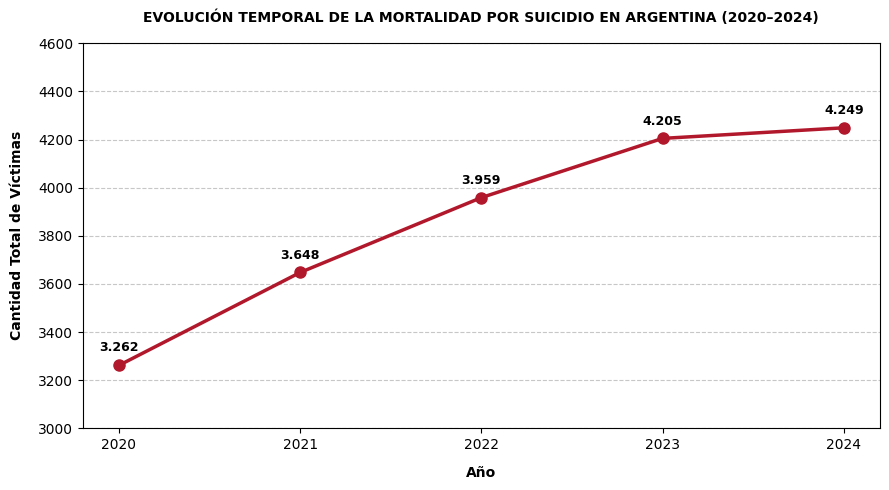

In [ ]:
#Importo la librería que vamos a usar
import matplotlib.pyplot as plt

#1. Filtramos la fila del acumulado 'total' para graficar únicamente la serie anual
df_grafico1 = resumen_anual[resumen_anual["anio"] != "total"].copy()

#2. Configuración de la figura y trazado de la línea
plt.figure(figsize=(9, 5))
plt.plot(
    df_grafico1["anio"].astype(str),
    df_grafico1["total_victimas"],
    marker="o",
    color="#b2182b",
    linewidth=2.5,
    markersize=8
)

#3. Pongo los títulos y las etiquetas correspondientes en los ejes
plt.title("EVOLUCIÓN TEMPORAL DE LA MORTALIDAD POR SUICIDIO EN ARGENTINA (2020–2024)", fontsize=10, fontweight="bold", pad=15)
plt.xlabel("Año", fontsize=10, fontweight="bold", labelpad=10)
plt.ylabel("Cantidad Total de Víctimas", fontsize=10, fontweight="bold", labelpad=10)

#4. Ajustes para mejorar el contraste visual
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.ylim(3000, 4600)

#5. Pongo etiquetas de valores numéricos sobre cada punto
for x, y in zip(df_grafico1["anio"].astype(str), df_grafico1["total_victimas"]):
    plt.annotate(
        f"{y:,}".replace(",", "."),
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

#6. Ajuste de márgenes y exportación de la imagen
plt.tight_layout()
plt.savefig("grafico1_evolucion_temporal_2020_2024.png", dpi=300, bbox_inches="tight")
plt.show()

**INTERPRETACIÓN:**

El gráfico de serie temporal muestra una subida exponencial en la cantidad anual de suicidios en Argentina a lo largo del período analizado. En 2020 se registró un piso de 3.262 víctimas, mientras que para el año 2024 la cifra alcanzó un techo de 4.249 muertes, lo que representa un incremento acumulado del 30,25% en tan solo cinco años.

Los datos confirman que el fenómeno mantuvo una trayectoria ascendente año tras año (3.262 en 2020; 3.648 en 2021; 3.959 en 2022; 4.205 en 2023; y 4.249 en 2024).

Esta continuidad en el aumento demuestra que la mortalidad por suicidio no responde a hechos aislados de un solo año, sino a una problemática de salud pública crítica y persistente que se consolida a lo largo del tiempo a nivel nacional.

### **GRÁFICO 2: Víctimas de suicidio por franja etaria**

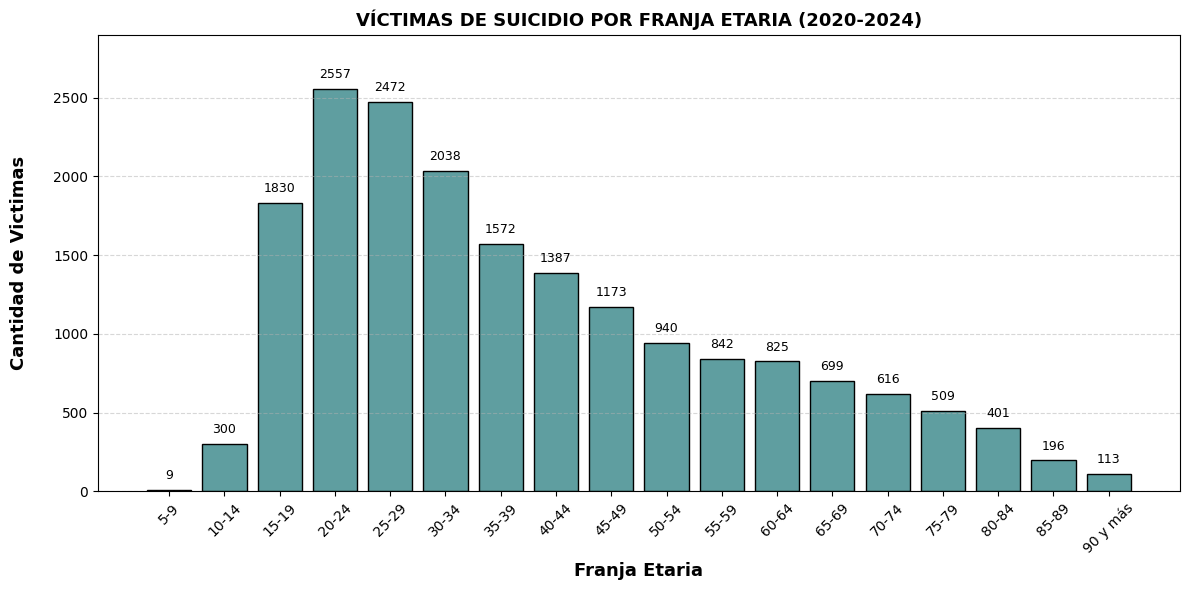

In [ ]:
#1. creamos la figura
plt.figure(figsize=(12,6))

#2. armamos un grafico de barras simple
plt.bar(conteo_edad["suicida_tr_edad"], conteo_edad["total_victimas"], color="cadetblue", edgecolor="black")

#3. Titulos y etiquetas
plt.title("VÍCTIMAS DE SUICIDIO POR FRANJA ETARIA (2020-2024)", fontsize=13, fontweight="bold")
plt.ylabel("Cantidad de Victimas", fontsize=13, fontweight="bold", labelpad=18)
plt.xlabel("Franja Etaria", fontsize=13, fontweight="bold")
plt.ylim(0,2900)

#4. Agregamos el número exacto en cada barra
for x,y in zip(conteo_edad["suicida_tr_edad"], conteo_edad["total_victimas"]):
    plt.text(x,y + 50, str(int(y)), ha="center", va="bottom", fontsize=9)

#5. Rotamos los nombres de los ejes para que se lean bien
plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)
plt.savefig("grafico2_sexo.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

**INTERPRETACIÓN:**

El gráfico evidencia una clara concentración de casos en las etapas tempranas de la vida adulta, destacándose como hallazgo principal en el dataset un marcado pico en la franja de los 15 a 34 años que reúne a la gran mayoría de las víctimas a nivel nacional (con máximos absolutos entre los 20 y 29 años, superando las 2.400 víctimas en el período de 5 años) y un descenso constante a partir de los 35 años a medida que avanza la edad.

Esto demuestra que el fenómeno en Argentina no se comporta de manera homogénea, sino que representa una problemática de salud pública fuertemente focalizada en los adolescentes y los adultos jóvenes.

###**GRÁFICO 3: Víctimas de suicidio por sexo**

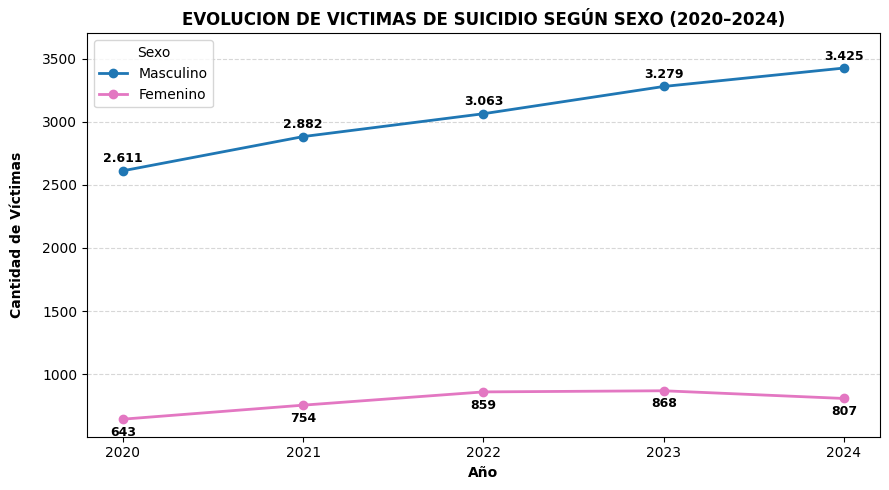

In [ ]:
#1. Agrupamos datos por año y sexo
df_sexo_piv = (
    df_master.groupby(["anio", "suicida_sexo"], observed=False)
    .size()
    .unstack(fill_value=0)
)

#2. Configuramos el gráfico de líneas superpuestas
plt.figure(figsize=(9, 5))

# Línea Masculino
plt.plot(
    df_sexo_piv.index,
    df_sexo_piv["Masculino"],
    marker="o",
    color="#1f77b4",
    linewidth=2,
    label="Masculino",
)

# Línea Femenino
plt.plot(
    df_sexo_piv.index,
    df_sexo_piv["Femenino"],
    marker="o",
    color="#e377c2",
    linewidth=2,
    label="Femenino",
)

#3. Ponemos las etiquetas numéricas sobre cada punto
for anio in df_sexo_piv.index:
    # Masculino
    v = df_sexo_piv.loc[anio, "Masculino"]
    plt.annotate(
        f"{v:,}".replace(",", "."),
        (anio, v),
        textcoords="offset points",
        xytext=(0, 6),
        ha="center",
        fontsize=9,
        fontweight="bold",
    )
    # Femenino
    m = df_sexo_piv.loc[anio, "Femenino"]
    plt.annotate(
        f"{m:,}".replace(",", "."),
        (anio, m),
        textcoords="offset points",
        xytext=(0, -12),
        ha="center",
        fontsize=9,
        fontweight="bold",
    )

#4. Formato final
plt.title(
    "EVOLUCION DE VICTIMAS DE SUICIDIO SEGÚN SEXO (2020–2024)",
    fontsize=12,
    fontweight="bold",)

plt.ylim(top=3700)
plt.xlabel("Año", fontweight="bold")
plt.ylabel("Cantidad de Víctimas", fontweight="bold", labelpad=13)
plt.xticks(df_sexo_piv.index)
plt.legend(title="Sexo")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("grafico3_sexo.png", dpi=300, bbox_inches="tight")

plt.show()


**Aclaración metodológica:** El gráfico presenta únicamente los registros clasificados como masculinos y femeninos. Los 132 casos (0,68% del total) cuyo sexo figura como «Sin determinar» no se representan en las líneas, ya que el objetivo es comparar ambas categorías. Sin embargo, estos registros permanecen incluidos en el dataset original y en los análisis generales de cantidades totales.

**INTERPRETACIÓN:**

El análisis de la evolución según sexo entre 2020 y 2024 refleja una marcada y sostenida brecha de género. Los varones concentran de forma sistemática la gran mayoría de los casos consumados, manteniendo una relación promedio aproximada de 4 a 1 respecto de las mujeres a lo largo de todo el período analizado. Asimismo, ambas series presentan una tendencia general al alza hacia el final de la serie, lo que muestra un incremento global de la problemática sin alterar la disparidad estructural entre ambos sexos.



### **GRAFICO 4: Promedio de suicidios por cada 100.000 habitantes por provincia**

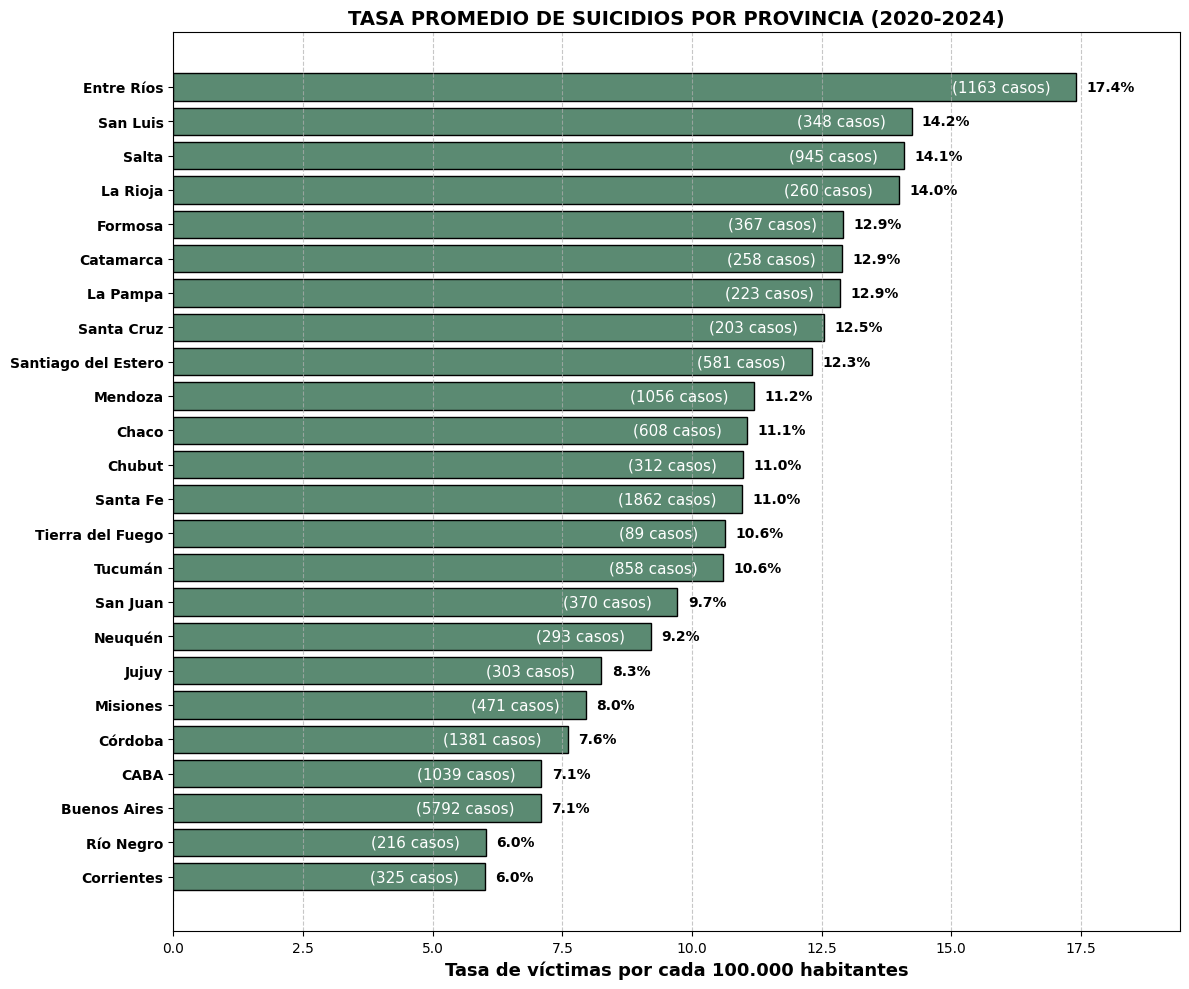

In [ ]:
# 1. Sacamos el promedio de la tasa y la suma de los casos por provincia
resumen_provincias = df_prov_suicidios.groupby("provincia_nombre").agg(
    tasa_promedio=("tasa_victimas", "mean"),
    casos_totales=("cantidad_victimas", "sum")
).reset_index()

# 2. Ordenamos de menor a mayor para que en el gráfico el más alto quede arriba
resumen_provincias = resumen_provincias.sort_values('tasa_promedio', ascending=True)

# 3. Acortamos los nombres de las provincias muy largas para que no ocupen tanto espacio
resumen_provincias["provincia_nombre"] = resumen_provincias["provincia_nombre"].replace({
    "Tierra del Fuego, Antártida e Islas del Atlántico Sur": "Tierra del Fuego",
    "Ciudad Autónoma de Buenos Aires": "CABA"
})

# 4. Creamos el gráfico de barras horizontales
fig, ax = plt.subplots(figsize=(12, 10))

# Cambiamos a 'darkslateblue' para que el texto interior blanco tenga un excelente contraste
y_pos= range(len(resumen_provincias))
bars= ax.barh(y_pos,
              resumen_provincias["tasa_promedio"],
              color="#5B8A72",
              edgecolor="black")
plt.yticks(fontweight="bold", fontsize=10)
# Asignamos las etiquetas del eje y
ax.set_yticks(y_pos)
ax.set_yticklabels(resumen_provincias["provincia_nombre"], fontweight="bold", fontsize=10)

# 5. Ponemos los números al final de las barras y adentro (los casos)
for i in range(len(resumen_provincias)):
    tasa = resumen_provincias["tasa_promedio"].iloc[i]
    casos = resumen_provincias["casos_totales"].iloc[i]

    # El número de la tasa, afuera de la barra
    ax.text(tasa + 0.2, i, f"{tasa:.1f}%", va="center", fontsize=10, fontweight="bold")

    # Los casos totales, adentro de la barra en blanco (ahora con contraste perfecto)
    ax.text(tasa - 0.5, i, f"({int(casos)} casos)", va='center', ha="right", fontsize=11, color="white")

# 6. Títulos y etiquetas
plt.title("TASA PROMEDIO DE SUICIDIOS POR PROVINCIA (2020-2024)", fontsize=14, fontweight="bold")
plt.xlabel("Tasa de víctimas por cada 100.000 habitantes", fontsize=13, fontweight="bold")


# 7. Ajustes para que se vea bien (grilla y límites)
ax.grid(axis="x", linestyle="--", alpha=0.7)
ax.set_xlim(0, resumen_provincias["tasa_promedio"].max() + 2.0)

# 8. Ajustamos los márgenes para que no quede tanto espacio en blanco a la izquierda
plt.tight_layout()


plt.savefig("grafico4_ranking.png", dpi=300, bbox_inches="tight")
plt.show()

**INTERPRETACION:**

El gráfico presenta la tasa promedio de suicidios cada 100.000 habitantes (2020-2024) y el total de víctimas acumuladas por provincia. El análisis ajustado por población revela una gran heterogeneidad territorial: jurisdicciones de menor densidad demográfica, como Tierra del Fuego o La Pampa, registran las tasas epidemiológicas más altas. En contraste, CABA y las provincias más pobladas exhiben índices menores, lo que demuestra que el riesgo individual no equivale al volumen absoluto de casos y refuerza la necesidad de priorizar los recursos de salud mental según la prevalencia local.